In [1]:
import warnings
from pathlib import Path
from tqdm import tqdm

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from phase_shift import PhaseConfig, PhaseSolver, remove_carrier, subtract_reference
from phase_shift.backend import asnumpy
from phase_shift.utils import wrap

def correct(stack, mask):
    ys, xs = np.where(mask)
    corr = stack.astype(float)          # astype already copies
    for y, x in zip(ys, xs):
        sl = (slice(max(0, y-1), y+2), slice(max(0, x-1), x+2))
        good = ~mask[sl]
        if good.any():
            corr[:, y, x] = np.median(stack[:, *sl][:, good], axis=1)
    return corr

def rob(x, k=5):                   # robust threshold, unbiased by outliers
        med = np.median(x)
        mad = np.median(np.abs(x-med))*1.4826
        return np.abs(x-med) >= k*mad


In [2]:
root = Path("/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261019_wvl_stack_500_700_5")

files = sorted(root.glob("*nm_*.npz"), key=lambda p: int(p.stem.split("_")[-3].removesuffix("nm")))
wavelengths = [int(p.stem.split("_")[-3].removesuffix("nm")) for p in files]
black_file = next(root.glob("*_black_*.npz"))

black_data = np.load(black_file)
black_frames = black_data["black"]
m = black_frames.mean(0)
s = black_frames.std(0)
mask = rob(m) | rob(s)

black_ref = m

In [ ]:
I_sample_arm_sample = []
I_ref_arm_sample = []
I_sample_arm_ref = []
I_ref_arm_ref = []
for file in tqdm(files):
    with np.load(file) as d:
        ref_arm_sample = d[d.files[2]]
        sample_arm_sample = d[d.files[3]]
        
        ref_arm_ref = d[d.files[5]]
        sample_arm_ref = d[d.files[5]]
    
    sample_arm_sample = correct(sample_arm_sample - black_ref, mask)
    ref_arm_sample = correct(ref_arm_sample - black_ref, mask)
    I_sample_arm_sample.append(sample_arm_sample.mean(0))
    I_ref_arm_sample.append(ref_arm_sample.mean(0))
    
    sample_arm_ref = correct(sample_arm_ref - black_ref, mask)
    ref_arm_ref = correct(ref_arm_ref - black_ref, mask)
    I_sample_arm_ref.append(sample_arm_ref.mean(0))
    I_ref_arm_ref.append(ref_arm_ref.mean(0))
    
I_sample_arm_sample = np.stack(I_sample_arm_sample)
I_ref_arm_sample = np.stack(I_ref_arm_sample)
I_sample_arm_ref = np.stack(I_sample_arm_ref)
I_ref_arm_ref = np.stack(I_ref_arm_ref)

I_sample = I_sample_arm_sample/I_ref_arm_sample
I_ref = I_sample_arm_ref/I_ref_arm_ref

I_ref_glass = I_sample/I_ref

del I_sample_arm_sample, I_ref_arm_sample, I_sample_arm_ref, I_ref_arm_ref

100%|██████████| 41/41 [01:46<00:00,  2.59s/it]


In [26]:
N = 15
orders = 3
precision = 'single'

use_alpha = True
gain_mode = "joint"
method = 'vp_aia'
method_kwargs = {"iters": 30, "tol": 1e-4, 
                 "basis": "poly", "basis_kwargs": {"degree": 2}, 
                 "orders": orders, "order_tol": 0.0,
                 "crop": 100}
carrier_degree = 2

config = PhaseConfig(use_alpha=use_alpha, gain_mode=gain_mode, method=method,
                     method_kwargs=method_kwargs, phi_error_simplified=True)
solver = PhaseSolver(config, precision=precision)

phi_stack = []
for file in tqdm(files):
    with np.load(file) as d:
        sample_stack = d[d.files[1]][0]
        ref_stack = d[d.files[4]][0]
        
    sample_stack = correct(sample_stack - black_ref, mask)
    result_sample = solver.fit(sample_stack[:N]).result
    phi_sample = remove_carrier(result_sample.phi, result_sample.b, degree=carrier_degree).phi
    
    ref_stack = correct(ref_stack - black_ref, mask)
    result_ref = solver.fit(ref_stack[:N]).result
    phi_ref = remove_carrier(result_ref.phi, result_ref.b, degree=carrier_degree).phi
    
    phi = subtract_reference(phi_sample, phi_ref, result_ref.b).phi
    phi_stack.append(phi)
    
phi_stack = np.stack(phi_stack)  
    

100%|██████████| 41/41 [15:08<00:00, 22.15s/it]


In [ ]:
# AIA for different N
precision = 'single'

use_alpha = True
gain_mode = "joint"
method = 'aia'
method_kwargs = {"iters": 30, "tol": 1e-4}
carrier_degree = 2

config = PhaseConfig(use_alpha=use_alpha, gain_mode=gain_mode, method=method,
                     method_kwargs=method_kwargs, phi_error_simplified=True)
solver = PhaseSolver(config, precision=precision)


phi_N_stack = []
for N in range(5, 16, 1):
    phi_stack = []
    for file in tqdm(files):
        with np.load(file) as d:
            sample_stack = d[d.files[1]][0]
            ref_stack = d[d.files[4]][0]
            
        sample_stack = correct(sample_stack - black_ref, mask)
        result_sample = solver.fit(sample_stack[:N]).result
        phi_sample = remove_carrier(result_sample.phi, result_sample.b, degree=carrier_degree).phi
        
        ref_stack = correct(ref_stack - black_ref, mask)
        result_ref = solver.fit(ref_stack[:N]).result
        phi_ref = remove_carrier(result_ref.phi, result_ref.b, degree=carrier_degree).phi
        
        phi = subtract_reference(phi_sample, phi_ref, result_ref.b).phi
        phi_stack.append(phi)
        
    phi_stack = np.stack(phi_stack)  
    phi_N_stack.append(phi_stack)
    
phi_N_stack = np.stack(phi_N_stack)  

  2%|▏         | 1/41 [00:04<03:14,  4.87s/it]

In [12]:
sample_stack[:16].shape

(16, 2200, 3300)

In [2]:
phi_stack = np.load("phi_stack.npz.npy")

In [6]:
def align_signs(phi_stack):
    """Put every map on the branch of phi_stack[0], chaining through neighbours."""
    out = phi_stack.copy()
    flips = []
    for k in range(1, len(out)):
        same = np.abs(np.exp(1j * (out[k] - out[k-1])).mean())   # 1 = identical
        flip = np.abs(np.exp(1j * (out[k] + out[k-1])).mean())
        if flip > same:
            out[k] = -out[k]
            flips.append(k)
    return out, flips

phi_stack, flips = align_signs(phi_stack)
print("flipped:", flips)

flipped: [1, 2, 3, 11, 12, 13, 14, 15, 16, 17, 19, 20, 23, 25, 26, 27, 28, 29, 33, 34, 37, 40]


In [14]:
def find_shift(ref, img, max_shift=40):
    """Integer (dy, dx) within ±max_shift that, rolled onto img, best aligns it with ref."""
    ref = ref - ref.mean(); img = img - img.mean()
    c = np.abs(np.fft.ifft2(np.fft.fft2(ref) * np.fft.fft2(img).conj()))
    c = np.fft.fftshift(c)                                   # zero shift at the centre
    H, W = c.shape; cy, cx = H // 2, W // 2
    win = c[cy - max_shift:cy + max_shift + 1, cx - max_shift:cx + max_shift + 1]
    dy, dx = np.unravel_index(win.argmax(), win.shape)
    return dy - max_shift, dx - max_shift

def align_stack(phi_stack, roi=(slice(250, 1250), slice(1000, 2000))):
    z = np.exp(1j * phi_stack[(slice(None),) + roi])       # ROI only: faster, ignores the edges
    shifts = [find_shift(z[0], zk) for zk in z]
    aligned = np.stack([np.roll(p, s, axis=(0, 1)) for p, s in zip(phi_stack, shifts)])
    return aligned, shifts

phi_aligned, shifts = align_stack(phi_stack)
print(shifts)

[(np.int64(0), np.int64(0)), (np.int64(-17), np.int64(0)), (np.int64(-17), np.int64(0)), (np.int64(-16), np.int64(0)), (np.int64(-16), np.int64(0)), (np.int64(-16), np.int64(-1)), (np.int64(-16), np.int64(-1)), (np.int64(-15), np.int64(-2)), (np.int64(-15), np.int64(-2)), (np.int64(-15), np.int64(-2)), (np.int64(-14), np.int64(-2)), (np.int64(-16), np.int64(-3)), (np.int64(-15), np.int64(-3)), (np.int64(-14), np.int64(-3)), (np.int64(-13), np.int64(-3)), (np.int64(-13), np.int64(-3)), (np.int64(-12), np.int64(-3)), (np.int64(-14), np.int64(-2)), (np.int64(-13), np.int64(-2)), (np.int64(-13), np.int64(-3)), (np.int64(-12), np.int64(-3)), (np.int64(-14), np.int64(-4)), (np.int64(-14), np.int64(-4)), (np.int64(-13), np.int64(-4)), (np.int64(-15), np.int64(-4)), (np.int64(-13), np.int64(-5)), (np.int64(-14), np.int64(-5)), (np.int64(-16), np.int64(-4)), (np.int64(-15), np.int64(-4)), (np.int64(-15), np.int64(-4)), (np.int64(-15), np.int64(-4)), (np.int64(-14), np.int64(-4)), (np.int64(-13)

In [15]:
from ipywidgets import interact

def show(stack, **imshow_kw):
    vmin, vmax = np.percentile(stack, [1, 99])   # fixed color scale across frames
    def frame(n=0):
        plt.figure(figsize=(8, 6))
        plt.imshow(stack[n], vmin=vmin, vmax=vmax, **imshow_kw)
        plt.xlim([1000, 2000])
        plt.ylim([250, 1250])
        plt.title(f"frame {n}")
        plt.colorbar()
        plt.show()
    interact(frame, n=(0, len(stack) - 1))

show(phi_aligned*180/np.pi)

interactive(children=(IntSlider(value=0, description='n', max=40), Output()), _dom_classes=('widget-interact',…

Glass Mean: -2.2341573238372803
Glass Std: 1.4911788702011108
Silicon Mean: -3.7029800415039062
Silicon Std: 2.639418125152588


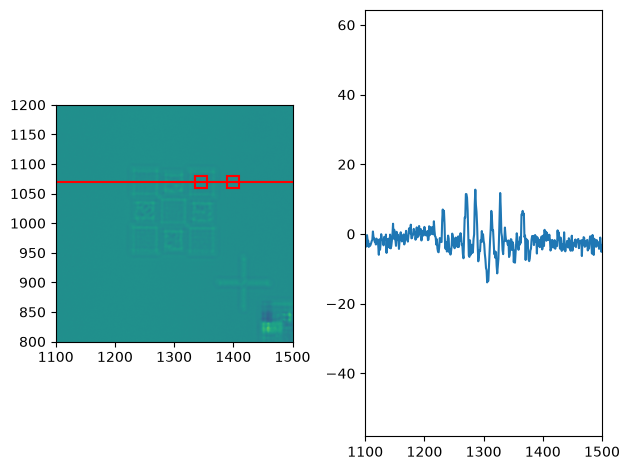

In [151]:
y_line = 1070

ax = plt.subplot(121)
plt.imshow(phi)
plt.ylim([800, 1200])
plt.xlim([1100, 1500])
plt.hlines(y_line, 1100, 1500, color='r')

xc1 = 1345
yc1 = 1070
side1 = 20

xc2 = 1400
yc2 = 1070
side2 = 20

squares = [(xc1 - side1//2, yc1 - side1//2, side1), (xc2 - side2//2, yc2 - side2//2, side2)]   # (x, y, side) in pixels
for x, y, s in squares:
    ax.add_patch(Rectangle((x, y), s, s, fill=False, edgecolor="red", linewidth=1.5))

plt.subplot(122)
plt.plot(phi[y_line]*180/np.pi)
plt.xlim([1100, 1500])

plt.tight_layout()

x, y, s = squares[1]
print(f"Glass Mean: {phi[y:y+s, x:x+s].mean() * 180/np.pi}")   # degrees
print(f"Glass Std: {phi[y:y+s, x:x+s].std() * 180/np.pi}")   # degrees

x, y, s = squares[0]
print(f"Silicon Mean: {phi[y:y+s, x:x+s].mean() * 180/np.pi}")   # degrees
print(f"Silicon Std: {phi[y:y+s, x:x+s].std() * 180/np.pi}")   # degrees

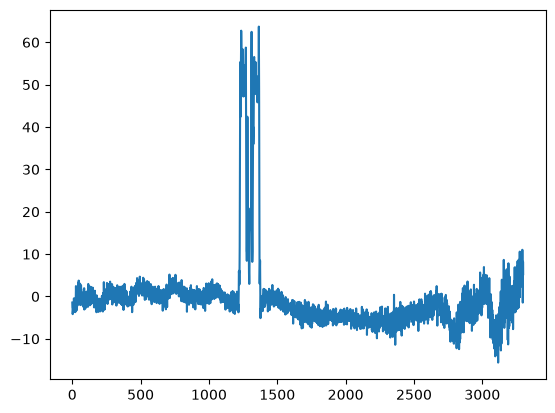

In [108]:
plt.plot(phi[y_line]*180/np.pi)

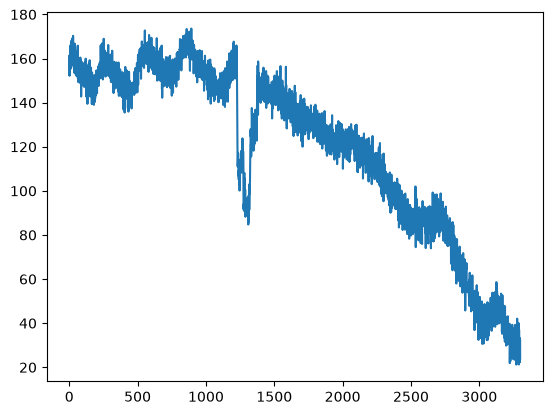

In [33]:
plt.plot((result.b)[1000])